# VLBI vs VLA percentage plots

### V407 Cyg, V3890 Sgr, V1535 Sco, RS Oph

In [1]:
#imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

## How we do a limit

upside down triangles mark the days that have day gaps in the VLBI and VLA data, and it is different within different parameters for the novae.

We went depending on the speed of evolution,

    If it is a quickly evolving nova, we made the upsdide down triangle 2+ days difference between the VLBI and VLA data, as there is more data variation between the days, and the flux can have dramatic changes between a few days.

    If it was a slowly evolving nova, we made the upside down triange 6-10+ days difference between the VLBI and VLA data, as there is less data variation between the days, the flux doesn't change much over a few days.

This was done after comparing the VLA and VLBI lightcurves together, and might change depending on the nova you look at. This worked for the 4 novae in this notebook.

# V407 Cyg

## 5 GHz and 1.6 GHz

## First 5 GHz

In [149]:
#VLBA observation
#from Giroletti et al. 2020

f5_VLBI = (
    [20, 5, 0.24, 0],  #EVN
    [31, 5, 1.8, 0], #VLBA
    [36, 5, 2.36, 0], #VLBA
    [70, 5, 7.1, 0], #EVN
    #[72, 5, 4.1, 0], #VLBA
    [182, 5, 0.5, 0],
)

#anything w/ 2 day diff
f5_VLBI_non = (
    #[20, 5, 0.24, 0],  #EVN
    #[31, 5, 1.8, 0], #VLBA
    #[36, 5, 2.36, 0], #VLBA
    #[70, 5, 7.1, 0], #EVN
    [72, 5, 4.1, 0], #VLBA
    #[182, 5, 0.5, 0],
)

#making the dataframes for the frequency
VLBI5_407 = pd.DataFrame(f5_VLBI, columns = ["Days","Freq","Flux","Error"])
days5_VLBI = VLBI5_407['Days']
flux5_VLBI = VLBI5_407["Flux"]
flux_err5_VLBI = np.sqrt(VLBI5_407["Error"]**2 + (VLBI5_407["Flux"]*0.05)**2)

VLBI5_407_non = pd.DataFrame(f5_VLBI_non, columns = ["Days","Freq","Flux","Error"])
days5_VLBI_non = VLBI5_407_non['Days']
flux5_VLBI_non = VLBI5_407_non["Flux"]
flux_err5_VLBI_non = np.sqrt(VLBI5_407_non["Error"]**2 + (VLBI5_407_non["Flux"]*0.05)**2)

In [150]:
#corresponding VLA data

#defing frequency 5
#anything under 4 days differnce
f5 = (
    #5 GHz
    #[55282.9,    1.0,  5.0,  6.389,  0.000,  0.150,  0.050],
    [55284.8,    2.0,  5.0,  7.034,  0.000,  0.104,  0.050],  # Day 19.6, 0.4 off
    #[55625.4,   25.0,  5.0,  5.003,  0.000,  0.027,  0.050],
    #[55735.4,   26.0,  5.0,  3.270,  0.000,  0.029,  0.050],
    #[55869.1,   27.0,  5.0,  3.542,  0.000,  0.036,  0.050],
    #[55934.8,   28.0,  5.0,  3.212,  0.055,  0.000,  0.050],
    #[56035.4,   29.0,  5.0,  2.913,  0.028,  0.000,  0.050], 
    #4.8 GHz
    #[55289.7,    3.0,  4.8,  6.880,  0.000,  0.130,  0.050],
    #[55294.7,    4.0,  4.8,  8.990,  0.000,  0.130,  0.050],
    [55298.7,    5.0,  4.8, 10.680,  0.000,  0.110,  0.050],  # Day 33.5, 2.5 off
    [55301.7,    6.0,  4.8, 12.363,  0.182,  0.051,  0.050],  # Day 36.5, 0.5 off
    #[55304.7,    7.0,  4.8, 12.792,  0.167,  0.039,  0.050],
    #[55308.7,    8.0,  4.8, 13.690,  0.171,  0.034,  0.050],
    #[55311.6,    9.0,  4.8, 13.964,  0.078,  0.014,  0.050],
    #[55315.6,   10.0,  4.8, 13.673,  0.107,  0.027,  0.050],
    #[55318.6,   11.0,  4.8, 13.135,  0.130,  0.028,  0.050],
    #[55323.6,   12.0,  4.8, 14.160,  0.088,  0.016,  0.050],
    #[55330.5,   13.0,  4.8, 15.023,  0.082,  0.023,  0.050],
    [55332.6,   14.0,  4.8, 15.479,  0.000,  0.155,  0.050],   # Day 67.4, 2.6 off
    #[55341.6,   15.0,  4.8, 17.395,  0.092,  0.032,  0.050],    # Day 76.4, 4.4 off
    #[55345.6,   16.0,  4.8, 17.465,  0.000,  0.165,  0.050],
    #[55362.5,   17.0,  4.8, 17.255,  0.061,  0.016,  0.050],
    #[55367.6,	  18.0,	4.8, 17.777,  0.145,  0.032,  0.050],	
    #[55368.5,	  19.0,	4.8, 17.446,  0.000,  0.135,  0.050],
    #[55404.4,   20.0,  4.8, 12.926,  0.083,  0.022,  0.050],
    #[55419.3,	  21.0,	4.8, 11.805,  0.118,  0.018,  0.050],
    #[55434.3,	  22.0,	4.8, 10.785,  0.100,  0.018,  0.050],
    [55449.2,	  23.0,  4.8,  9.979,  0.115,  0.024,  0.050],  # Day 184, 2 off
    #[55469.2,	  24.0,	4.8,  9.173,  0.074,  0.000,  0.050], 
)

#anything over 4 days
f5_non = (
    #5 GHz
    #[55282.9,    1.0,  5.0,  6.389,  0.000,  0.150,  0.050],
    #[55284.8,    2.0,  5.0,  7.034,  0.000,  0.104,  0.050],  # Day 19.6, 0.4 off
    #[55625.4,   25.0,  5.0,  5.003,  0.000,  0.027,  0.050],
    #[55735.4,   26.0,  5.0,  3.270,  0.000,  0.029,  0.050],
    #[55869.1,   27.0,  5.0,  3.542,  0.000,  0.036,  0.050],
    #[55934.8,   28.0,  5.0,  3.212,  0.055,  0.000,  0.050],
    #[56035.4,   29.0,  5.0,  2.913,  0.028,  0.000,  0.050], 
    #4.8 GHz
    #[55289.7,    3.0,  4.8,  6.880,  0.000,  0.130,  0.050],
    #[55294.7,    4.0,  4.8,  8.990,  0.000,  0.130,  0.050],
    #[55298.7,    5.0,  4.8, 10.680,  0.000,  0.110,  0.050],  # Day 33.5, 2.5 off
    #[55301.7,    6.0,  4.8, 12.363,  0.182,  0.051,  0.050],  # Day 36.5, 0.5 off
    #[55304.7,    7.0,  4.8, 12.792,  0.167,  0.039,  0.050],
    #[55308.7,    8.0,  4.8, 13.690,  0.171,  0.034,  0.050],
    #[55311.6,    9.0,  4.8, 13.964,  0.078,  0.014,  0.050],
    #[55315.6,   10.0,  4.8, 13.673,  0.107,  0.027,  0.050],
    #[55318.6,   11.0,  4.8, 13.135,  0.130,  0.028,  0.050],
    #[55323.6,   12.0,  4.8, 14.160,  0.088,  0.016,  0.050],
    #[55330.5,   13.0,  4.8, 15.023,  0.082,  0.023,  0.050],
    #[55332.6,   14.0,  4.8, 15.479,  0.000,  0.155,  0.050],   # Day 67.4, 2.6 off
    [55341.6,   15.0,  4.8, 17.395,  0.092,  0.032,  0.050],    # Day 76.4, 4.4 off
    #[55345.6,   16.0,  4.8, 17.465,  0.000,  0.165,  0.050],
    #[55362.5,   17.0,  4.8, 17.255,  0.061,  0.016,  0.050],
    #[55367.6,	  18.0,	4.8, 17.777,  0.145,  0.032,  0.050],	
    #[55368.5,	  19.0,	4.8, 17.446,  0.000,  0.135,  0.050],
    #[55404.4,   20.0,  4.8, 12.926,  0.083,  0.022,  0.050],
    #[55419.3,	  21.0,	4.8, 11.805,  0.118,  0.018,  0.050],
    #[55434.3,	  22.0,	4.8, 10.785,  0.100,  0.018,  0.050],
    #[55449.2,	  23.0,  4.8,  9.979,  0.115,  0.024,  0.050],  # Day 184, 2 off
    #[55469.2,	  24.0,	4.8,  9.173,  0.074,  0.000,  0.050], 
)


#making the dataframes for the frequency
VLA5_407 = pd.DataFrame(f5, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])
days5_VLA = VLA5_407['MJD']-55265.2
flux5_VLA = VLA5_407["Flux"]
flux_err5_VLA = np.sqrt(VLA5_407["Error1 (gaussfit)"]**2 + (VLA5_407["Flux"]*0.05)**2)

VLA5_407_non = pd.DataFrame(f5_non, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])
days5_VLA_non = VLA5_407_non['MJD']-55265.2
flux5_VLA_non = VLA5_407_non["Flux"]
flux_err5_VLA_non = np.sqrt(VLA5_407_non["Error1 (gaussfit)"]**2 + (VLA5_407_non["Flux"]*0.05)**2)

In [151]:
#finding the difference between the VLBI and VLA data
diff_V407_5GHz = flux5_VLBI/flux5_VLA

diff_V407_5GHz_non = flux5_VLBI_non/flux5_VLA_non


In [152]:
#averaging the days?
day_V407_5GHz = (days5_VLA + days5_VLBI)/2

day_V407_5GHz_non = (days5_VLA_non + days5_VLBI_non)/2

In [153]:
#all of them to plot the lines
f5_VLBI_plot = (
    [20, 5, 0.24, 0],  #EVN
    [31, 5, 1.8, 0], #VLBA
    [36, 5, 2.36, 0], #VLBA
    [70, 5, 7.1, 0], #EVN
    [72, 5, 4.1, 0], #VLBA
    [182, 5, 0.5, 0],
)

VLBI5_407_plot = pd.DataFrame(f5_VLBI_plot, columns = ["Days","Freq","Flux","Error"])
days5_VLBI_plot = VLBI5_407_plot['Days']
flux5_VLBI_plot = VLBI5_407_plot["Flux"]

f5_plot = (
    #5 GHz
    #[55282.9,    1.0,  5.0,  6.389,  0.000,  0.150,  0.050],
    [55284.8,    2.0,  5.0,  7.034,  0.000,  0.104,  0.050],  # Day 19.6, 0.4 off
    #[55625.4,   25.0,  5.0,  5.003,  0.000,  0.027,  0.050],
    #[55735.4,   26.0,  5.0,  3.270,  0.000,  0.029,  0.050],
    #[55869.1,   27.0,  5.0,  3.542,  0.000,  0.036,  0.050],
    #[55934.8,   28.0,  5.0,  3.212,  0.055,  0.000,  0.050],
    #[56035.4,   29.0,  5.0,  2.913,  0.028,  0.000,  0.050], 
    #4.8 GHz
    #[55289.7,    3.0,  4.8,  6.880,  0.000,  0.130,  0.050],
    #[55294.7,    4.0,  4.8,  8.990,  0.000,  0.130,  0.050],
    [55298.7,    5.0,  4.8, 10.680,  0.000,  0.110,  0.050],  # Day 33.5, 2.5 off
    [55301.7,    6.0,  4.8, 12.363,  0.182,  0.051,  0.050],  # Day 36.5, 0.5 off
    #[55304.7,    7.0,  4.8, 12.792,  0.167,  0.039,  0.050],
    #[55308.7,    8.0,  4.8, 13.690,  0.171,  0.034,  0.050],
    #[55311.6,    9.0,  4.8, 13.964,  0.078,  0.014,  0.050],
    #[55315.6,   10.0,  4.8, 13.673,  0.107,  0.027,  0.050],
    #[55318.6,   11.0,  4.8, 13.135,  0.130,  0.028,  0.050],
    #[55323.6,   12.0,  4.8, 14.160,  0.088,  0.016,  0.050],
    #[55330.5,   13.0,  4.8, 15.023,  0.082,  0.023,  0.050],
    [55332.6,   14.0,  4.8, 15.479,  0.000,  0.155,  0.050],   # Day 67.4, 2.6 off
    [55341.6,   15.0,  4.8, 17.395,  0.092,  0.032,  0.050],    # Day 76.4, 4.4 off
    #[55345.6,   16.0,  4.8, 17.465,  0.000,  0.165,  0.050],
    #[55362.5,   17.0,  4.8, 17.255,  0.061,  0.016,  0.050],
    #[55367.6,	  18.0,	4.8, 17.777,  0.145,  0.032,  0.050],	
    #[55368.5,	  19.0,	4.8, 17.446,  0.000,  0.135,  0.050],
    #[55404.4,   20.0,  4.8, 12.926,  0.083,  0.022,  0.050],
    #[55419.3,	  21.0,	4.8, 11.805,  0.118,  0.018,  0.050],
    #[55434.3,	  22.0,	4.8, 10.785,  0.100,  0.018,  0.050],
    [55449.2,	  23.0,  4.8,  9.979,  0.115,  0.024,  0.050],  # Day 184, 2 off
    #[55469.2,	  24.0,	4.8,  9.173,  0.074,  0.000,  0.050], 
)
VLA5_407_plot = pd.DataFrame(f5_plot, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])
days5_VLA_plot = VLA5_407_plot['MJD']-55265.2
flux5_VLA_plot = VLA5_407_plot["Flux"]

diff_V407_5GHz_plot = flux5_VLBI_plot/flux5_VLA_plot
day_V407_5GHz_plot = (days5_VLA_plot + days5_VLBI_plot)/2

## 1.6 GHz

In [154]:
#VLBA observation
#from Giroletti et al. 2020
#all days have a difference less than 2 days

f1_VLBI = (
    [44, 1.6, 2.4, 0], #EVN
    [55, 1.6, 1.8, 0], #VLBA
    [72, 1.6, 1.7, 0], #VLBA
    #[91, 1.6, 4.0, 0], #EVN
    [203, 1.6, 3.9, 0] #EVN
)

#making the dataframes for the frequency
VLBI_407_1 = pd.DataFrame(f1_VLBI, columns = ["Days","Freq","Flux","Error"])
days1_VLBI = VLBI_407_1['Days']
flux1_VLBI = VLBI_407_1["Flux"]
flux_err1_VLBI = np.sqrt(VLBI_407_1["Error"]**2 + (VLBI_407_1["Flux"]*0.05)**2)


#non VLBA observation, 2 days+ difference
#from Giroletti et al. 2020

f1_VLBI_non = (
    #[44, 1.6, 2.4, 0], #EVN
    #[55, 1.6, 1.8, 0], #VLBA
    #[72, 1.6, 1.7, 0], #VLBA
    [91, 1.6, 4.0, 0], #EVN
    #[203, 1.6, 3.9, 0] #EVN
)

#making the dataframes for the frequency
VLBI_407_1_non = pd.DataFrame(f1_VLBI_non, columns = ["Days","Freq","Flux","Error"])

days1_VLBI_non = VLBI_407_1_non['Days']
flux1_VLBI_non = VLBI_407_1_non["Flux"]
flux_err1_VLBI_non = np.sqrt(VLBI_407_1_non["Error"]**2 + (VLBI_407_1_non["Flux"]*0.05)**2)

In [155]:
#VLA data

#defing frequency 1.8
#all days with a difference less than 5 days
f1 = (
    # [55289.7,    3.0,  1.8,  3.469,  0.350,  0.000,  0.050],
    #[55298.7,    5.0,  1.8,  4.762,  0.300,  0.000,  0.050],
    #[55301.7,    6.0,  1.8,  5.466,  0.300,  0.000,  0.050],
    #[55304.7,    7.0,  1.8,  5.512,  0.350,  0.000,  0.050],
    [55308.7,    8.0,  1.8,  6.662,  0.330,  0.000,  0.050], #Day 43.5, 0.5 days off
    #[55311.7,    9.0,  1.8,  6.841,  0.300,  0.000,  0.050],
    #[55315.6,   10.0,  1.8,  7.376,  0.290,  0.000,  0.050],
    [55318.6 ,  11.0,  1.8,  7.478,  0.260,  0.000,  0.050],  #day 53.4, 1.6 days off
    #[55323.6,   12.0,  1.8,  7.657,  0.330,  0.000,  0.050],
    #[55330.5,   13.0,  1.8,  6.651,  0.270,  0.000,  0.050],
    #[55332.6,   14.0,  1.8,  7.574,  0.260,  0.000,  0.050],
    [55341.6,   15.0,  1.8,  8.049,  0.260,  0.000,  0.050],  #Day 76.4, 4.4 days off
    #[55345.6,   16.0,  1.8,  7.532,  0.280,  0.000 , 0.050],
    #[55362.5,   17.0,	1.8,  7.540,  0.240,  0.000,  0.050],  #Day 97.3, 6.3 days off
    #[55367.6,	  18.0,  1.8,  7.811,  0.290,  0.000,  0.050],
    #[55368.5,	  19.0,  1.8,  7.381,  0.260,  0.000,  0.050],
    #[55404.4 ,  20.0,  1.8 , 8.225,  0.300,  0.000,  0.050],
    #[55419.4,	  21.0,	1.8,  8.192 , 0.200,  0.000,  0.050],
    #[55434.3,	  22.0,	1.8,  6.386,  0.240,  0.000,  0.050],
    #[55449.2,	  23.0, 	1.8,  6.338,  0.160,  0.000,  0.050],
    [55469.2,	  24.0,	1.8,  5.532,  0.135,  0.000,  0.050],  #Day 204, 1 day off
    #[55625.4,   25.0,  1.8,  4.644,  0.092,  0.000 , 0.050],
    #[55735.4,   26.0,  1.8,  4.074,  0.068,  0.000,  0.050],
    #[55869.1 ,  27.0,  1.8,  3.855,  0.291,  0.000,  0.050],
    #[55934.8,   28.0,  1.8,  3.316,  0.554,  0.000,  0.050], #held width constant
    #[56035.4,   29.0,  1.8,  3.347,  0.232,  0.000,  0.050]
)

#making the dataframes for the frequency
VLA_407_1 = pd.DataFrame(f1, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])
days1_VLA = VLA_407_1['MJD']-55265.2
flux1_VLA = VLA_407_1["Flux"]
flux_err1_VLA = np.sqrt(VLA_407_1["Error1 (gaussfit)"]**2 + (VLA_407_1["Flux"]*0.05)**2)


#all days with a difference more than 5 days

f1_non = (
    # [55289.7,    3.0,  1.8,  3.469,  0.350,  0.000,  0.050],
    #[55298.7,    5.0,  1.8,  4.762,  0.300,  0.000,  0.050],
    #[55301.7,    6.0,  1.8,  5.466,  0.300,  0.000,  0.050],
    #[55304.7,    7.0,  1.8,  5.512,  0.350,  0.000,  0.050],
    #[55308.7,    8.0,  1.8,  6.662,  0.330,  0.000,  0.050], #Day 43.5, 0.5 days off
    #[55311.7,    9.0,  1.8,  6.841,  0.300,  0.000,  0.050],
    #[55315.6,   10.0,  1.8,  7.376,  0.290,  0.000,  0.050],
    #[55318.6 ,  11.0,  1.8,  7.478,  0.260,  0.000,  0.050],  #day 53.4, 1.6 days off
    #[55323.6,   12.0,  1.8,  7.657,  0.330,  0.000,  0.050],
    #[55330.5,   13.0,  1.8,  6.651,  0.270,  0.000,  0.050],
    #[55332.6,   14.0,  1.8,  7.574,  0.260,  0.000,  0.050],
    #[55341.6,   15.0,  1.8,  8.049,  0.260,  0.000,  0.050],  #Day 76.4, 4.4 days off
    #[55345.6,   16.0,  1.8,  7.532,  0.280,  0.000 , 0.050],
    [55362.5,   17.0,	1.8,  7.540,  0.240,  0.000,  0.050],  #Day 97.3, 6.3 days off
    #[55367.6,	  18.0,  1.8,  7.811,  0.290,  0.000,  0.050],
    #[55368.5,	  19.0,  1.8,  7.381,  0.260,  0.000,  0.050],
    #[55404.4 ,  20.0,  1.8 , 8.225,  0.300,  0.000,  0.050],
    #[55419.4,	  21.0,	1.8,  8.192 , 0.200,  0.000,  0.050],
    #[55434.3,	  22.0,	1.8,  6.386,  0.240,  0.000,  0.050],
    #[55449.2,	  23.0, 	1.8,  6.338,  0.160,  0.000,  0.050],
    #[55469.2,	  24.0,	1.8,  5.532,  0.135,  0.000,  0.050],  #Day 204, 1 day off
    #[55625.4,   25.0,  1.8,  4.644,  0.092,  0.000 , 0.050],
    #[55735.4,   26.0,  1.8,  4.074,  0.068,  0.000,  0.050],
    #[55869.1 ,  27.0,  1.8,  3.855,  0.291,  0.000,  0.050],
    #[55934.8,   28.0,  1.8,  3.316,  0.554,  0.000,  0.050], #held width constant
    #[56035.4,   29.0,  1.8,  3.347,  0.232,  0.000,  0.050]
)




#making the dataframes for the frequency
VLA_407_1_non = pd.DataFrame(f1_non, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])
days1_VLA_non = VLA_407_1_non['MJD']-55265.2
flux1_VLA_non = VLA_407_1_non["Flux"]
flux_err1_VLA_non = np.sqrt(VLA_407_1_non["Error1 (gaussfit)"]**2 + (VLA_407_1_non["Flux"]*0.05)**2)

In [156]:
#finding the difference between the VLBI and VLA data
diff_V407_1GHz = flux1_VLBI/flux1_VLA

diff_V407_1GHz_non = flux1_VLBI_non/flux1_VLA_non


#averaging the days?
day_V407_1GHz = (days1_VLA + days1_VLBI)/2

day_V407_1GHz_non = (days1_VLA_non + days1_VLBI_non)/2

In [157]:
f1_VLBI_plot = (
    [44, 1.6, 2.4, 0], #EVN
    [55, 1.6, 1.8, 0], #VLBA
    [72, 1.6, 1.7, 0], #VLBA
    [91, 1.6, 4.0, 0], #EVN
    [203, 1.6, 3.9, 0] #EVN
)

#making the dataframes for the frequency
VLBI_407_1_plot = pd.DataFrame(f1_VLBI_plot, columns = ["Days","Freq","Flux","Error"])
days1_VLBI_plot = VLBI_407_1_plot['Days']
flux1_VLBI_plot = VLBI_407_1_plot["Flux"]


f1_plot = (
    # [55289.7,    3.0,  1.8,  3.469,  0.350,  0.000,  0.050],
    #[55298.7,    5.0,  1.8,  4.762,  0.300,  0.000,  0.050],
    #[55301.7,    6.0,  1.8,  5.466,  0.300,  0.000,  0.050],
    #[55304.7,    7.0,  1.8,  5.512,  0.350,  0.000,  0.050],
    [55308.7,    8.0,  1.8,  6.662,  0.330,  0.000,  0.050], #Day 43.5, 0.5 days off
    #[55311.7,    9.0,  1.8,  6.841,  0.300,  0.000,  0.050],
    #[55315.6,   10.0,  1.8,  7.376,  0.290,  0.000,  0.050],
    [55318.6 ,  11.0,  1.8,  7.478,  0.260,  0.000,  0.050],  #day 53.4, 1.6 days off
    #[55323.6,   12.0,  1.8,  7.657,  0.330,  0.000,  0.050],
    #[55330.5,   13.0,  1.8,  6.651,  0.270,  0.000,  0.050],
    #[55332.6,   14.0,  1.8,  7.574,  0.260,  0.000,  0.050],
    [55341.6,   15.0,  1.8,  8.049,  0.260,  0.000,  0.050],  #Day 76.4, 4.4 days off
    #[55345.6,   16.0,  1.8,  7.532,  0.280,  0.000 , 0.050],
    [55362.5,   17.0,	1.8,  7.540,  0.240,  0.000,  0.050],  #Day 97.3, 6.3 days off
    #[55367.6,	  18.0,  1.8,  7.811,  0.290,  0.000,  0.050],
    #[55368.5,	  19.0,  1.8,  7.381,  0.260,  0.000,  0.050],
    #[55404.4 ,  20.0,  1.8 , 8.225,  0.300,  0.000,  0.050],
    #[55419.4,	  21.0,	1.8,  8.192 , 0.200,  0.000,  0.050],
    #[55434.3,	  22.0,	1.8,  6.386,  0.240,  0.000,  0.050],
    #[55449.2,	  23.0, 	1.8,  6.338,  0.160,  0.000,  0.050],
    [55469.2,	  24.0,	1.8,  5.532,  0.135,  0.000,  0.050],  #Day 204, 1 day off
    #[55625.4,   25.0,  1.8,  4.644,  0.092,  0.000 , 0.050],
    #[55735.4,   26.0,  1.8,  4.074,  0.068,  0.000,  0.050],
    #[55869.1 ,  27.0,  1.8,  3.855,  0.291,  0.000,  0.050],
    #[55934.8,   28.0,  1.8,  3.316,  0.554,  0.000,  0.050], #held width constant
    #[56035.4,   29.0,  1.8,  3.347,  0.232,  0.000,  0.050]
)

#making the dataframes for the frequency
VLA_407_1_plot = pd.DataFrame(f1_plot, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])
days1_VLA_plot = VLA_407_1_plot['MJD']-55265.2
flux1_VLA_plot = VLA_407_1_plot["Flux"]


diff_V407_1GHz_plot = flux1_VLBI_plot/flux1_VLA_plot
day_V407_1GHz_plot = (days1_VLA_plot + days1_VLBI_plot)/2

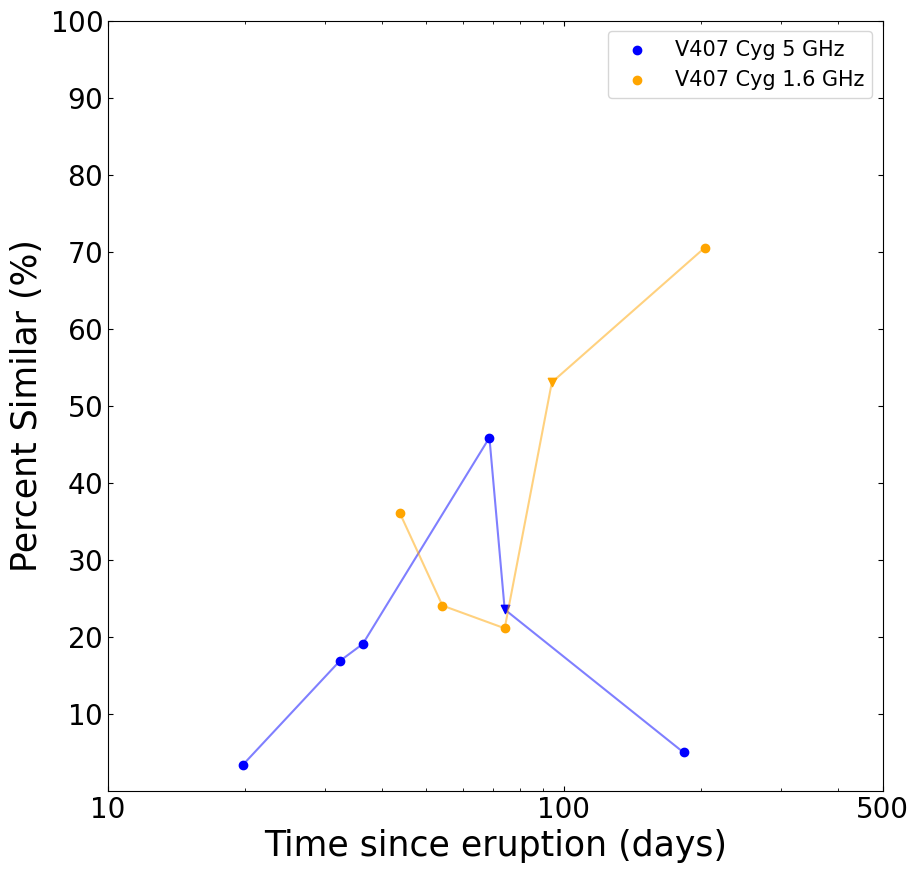

In [158]:
#plotting
fig, ax = plt.subplots()
fig.set_size_inches(10,10)

ax.scatter(day_V407_5GHz, diff_V407_5GHz*100, color='blue', marker='o', label="V407 Cyg 5 GHz")
ax.scatter(day_V407_5GHz_non, diff_V407_5GHz_non*100, color='blue', marker='v')
ax.plot(day_V407_5GHz_plot, diff_V407_5GHz_plot*100, color='blue', alpha=0.5)


ax.scatter(day_V407_1GHz, diff_V407_1GHz*100, color='orange', marker='o', label="V407 Cyg 1.6 GHz")
ax.scatter(day_V407_1GHz_non, diff_V407_1GHz_non*100, color='orange', marker='v')
ax.plot(day_V407_1GHz_plot, diff_V407_1GHz_plot*100, color='orange', alpha=0.5)

# Final plot formatting
#x-axis
ax.set_xscale('log')
ax.set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 20)
ax.set_xlabel("Time since eruption (days)", fontsize = 25)
#y-axis
#ax.set_yscale('log')
ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels = [r'$10$', r'$20$', r'$30$', r'$40$', r'$50$', r'$60$', r'$70$', r'$80$', r'$90$', r'$100$'], fontsize = 20)
ax.set_ylabel("Percent Similar (%)", fontsize = 25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.set_title("")
plt.legend(fontsize = 15)
#plt.savefig("V407Cyg_VLA_vs_VLBA_percent_.png")
plt.show()

# V3890 Sgr

## 4.87/4.93 GHz and 8.37 GHz

### 5 GHz

In [159]:
#VLBA data
#from I. Molina et al. 2026

f5 = (
    [8.1, 4.87, 37.75, 4.17],
    [16.1, 4.87, 36.41, 2.02],
    [32, 4.87, 24.61, 1.37],
    [48.7, 4.93, 12.44, 0.64], #from MERLIN, bright nova shell
    [48.7, 4.93, 17.15, 0.94], #from MERLIN, bright nova shell and the diffuse emission around the shell
    [51, 4.87, 14, 0.8]
    
)

VLBA_5_V3890 = pd.DataFrame(f5, columns = ["Day", "Frequency", "Flux Density", "Uncertainty"])


days_VLBA_5_V3890 = VLBA_5_V3890['Day']
flux_VLBA_5_V3890 = VLBA_5_V3890["Flux Density"]
flux_err_VLBA_5_V3890 = np.sqrt(VLBA_5_V3890["Uncertainty"]**2 + ( VLBA_5_V3890["Flux Density"]*0.05)**2)

In [160]:
#VLA data
#from I. Molina et al. 2026
f5 = (
    [8.1, 4.87, 43.5, 2.2],
    [16.1, 4.87, 44, 2.2],
    [32, 4.87, 24.8, 1.2],
    [48.7, 4.93, 17.3, 0.9], 
    [48.7, 4.93, 17.3, 0.9], 
    [51, 4.87, 17.3, 0.9]
    
)

VLA_5_V3890 = pd.DataFrame(f5, columns = ["Day", "Frequency", "Flux Density", "Uncertainty"])


days_VLA_5_V3890 = VLA_5_V3890['Day']
flux_VLA_5_V3890 = VLA_5_V3890["Flux Density"]
flux_err_VLA_5_V3890 = np.sqrt(VLA_5_V3890["Uncertainty"]**2 + ( VLA_5_V3890["Flux Density"]*0.05)**2)

In [161]:
#finding the difference between the VLBI and VLA data
diff_V3890_5GHz = flux_VLBA_5_V3890 /flux_VLA_5_V3890 


#averaging the days
day_V3890_5GHz = (days_VLA_5_V3890 + days_VLBA_5_V3890)/2


### 8.4 GHZ

In [162]:
#VLBI data
#from I. Molina et al. 2026


f8 = (
    [8.1, 8.37, 36.91, 2.37],
    [16, 8.37, 32.68, 1.75]
)

VLBA_8_V3890 = pd.DataFrame(f8, columns = ["Day", "Frequency", "Flux Density", "Uncertainty"])


days_VLBA_8_V3890 = VLBA_8_V3890['Day']
flux_VLBA_8_V3890 = VLBA_8_V3890["Flux Density"]
flux_err_VLBA_8_V3890 = np.sqrt(VLBA_8_V3890["Uncertainty"]**2 + ( VLBA_8_V3890["Flux Density"]*0.05)**2)

In [163]:
#VLA data
#from I. Molina et al. 2026

f8 = (
    [8.1, 8.37, 44.6, 2.2], 
    [16, 8.37, 39.9, 2.0]
)

VLA_8_V3890 = pd.DataFrame(f8, columns = ["Day", "Frequency", "Flux Density", "Uncertainty"])


days_VLA_8_V3890 = VLA_8_V3890['Day']
flux_VLA_8_V3890 = VLA_8_V3890["Flux Density"]
flux_err_VLA_8_V3890 = np.sqrt(VLA_8_V3890["Uncertainty"]**2 + ( VLA_8_V3890["Flux Density"]*0.05)**2)

In [164]:
#finding the difference between the VLBI and VLA data
diff_V3890_8GHz = flux_VLBA_8_V3890 /flux_VLA_8_V3890 


#averaging the days
day_V3890_8GHz = (days_VLA_8_V3890 + days_VLBA_8_V3890)/2

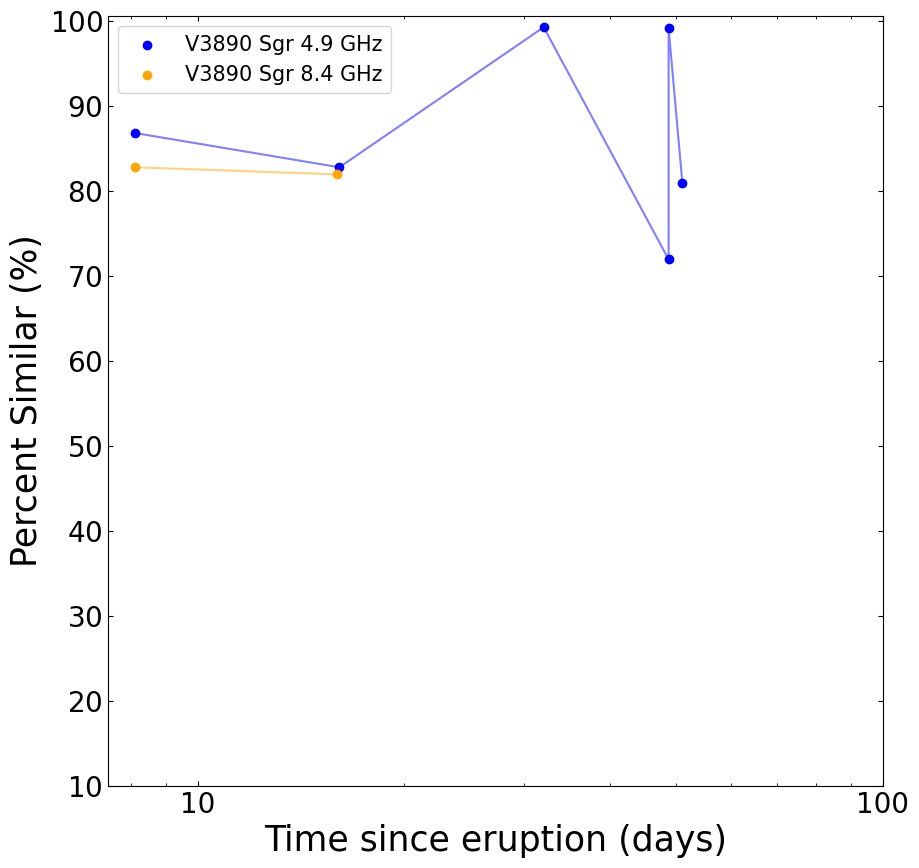

In [165]:
#plotting
fig, ax = plt.subplots()
fig.set_size_inches(10,10)

ax.scatter(day_V3890_5GHz, diff_V3890_5GHz*100, color='blue', marker='o', label="V3890 Sgr 4.9 GHz")
ax.plot(day_V3890_5GHz, diff_V3890_5GHz*100, color='blue', alpha=0.5)


ax.scatter(day_V3890_8GHz, diff_V3890_8GHz*100, color='orange', marker='o', label="V3890 Sgr 8.4 GHz")
ax.plot(day_V3890_8GHz, diff_V3890_8GHz*100, color='orange', alpha=0.5)

# Final plot formatting
#x-axis
ax.set_xscale('log')
ax.set_xticks([ 10,100], labels = ['10','100'], fontsize = 20)
ax.set_xlabel("Time since eruption (days)", fontsize = 25)
#y-axis
#ax.set_yscale('log')
ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels = [r'$10$', r'$20$', r'$30$', r'$40$', r'$50$', r'$60$', r'$70$', r'$80$', r'$90$', r'$100$'], fontsize = 20)
ax.set_ylabel("Percent Similar (%)", fontsize = 25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.set_title("")
plt.legend(fontsize = 15)
#plt.savefig("V3890Sgr_VLA_vs_VLBA_percent_.png")
plt.show()

# V1535 Sco

## only 4.87 GHz

In [166]:
#VLBA data

f4_87 = (
    #from Justin (in excel sheet)
    [57077.7, 4.87, 0.155, 0.0409], #VLBA, Day 12.863
    [57072.5, 4.87, 0.484, 0.0505], #VLBA, Day 7.663
    #from Linford et al 2017
    #[7.663, 4.87, 177.3, 0.477, 0.056],
    #[12.763, 4.87, 177.3, 0.278, 0.041]
)

VLBA_1535 = pd.DataFrame(f4_87, columns = ["Day", "Frequency", "Flux Density", "Uncertainty"])


days_VLBA_1535 = VLBA_1535['Day'] - 57064.837
flux_VLBA_1535 = VLBA_1535["Flux Density"]
flux_err_VLBA_1535 = np.sqrt(VLBA_1535["Uncertainty"]**2 + ( VLBA_1535["Flux Density"]*0.05)**2)

In [167]:
#VLA data

f4_55 = (#[57360.7, 5, 0.0795, 0.031],#D
         #[57187.2, 5, 0.0194, 0.0204],#BnA _> A
         #[57158.3, 4.55, 0.0727, 0.023],#B_> BnA
         #[57143.3, 4.55, 0.17, 0.0183],
         #[57130.35, 4.55, 0.256, 0.0172],
         #[57120.57, 4.55, 0.483, 0.0191],
         #[57106.47, 4.55, 0.222, 0.0161],
         #[57091.4, 4.55, 0.455, 0.0187],
         [57082.5, 4.55, 0.221, 0.0181],  #Day 17.663, 4.3 days off
         [57072.5, 4.55, 0.65, 0.0168],  #Day 7.663, 0 days off
         #[57067.5, 4.55, 4.132, 0.0203],#B
        )

df4_55_VLA_1535 =  pd.DataFrame(f4_55, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

days4_55_VLA_1535 = df4_55_VLA_1535['MJD'] - 57064.837
flux4_55_VLA_1535 = df4_55_VLA_1535["Flux Density (mJy)"]
flux_err4_55_VLA_1535 = np.sqrt(df4_55_VLA_1535["Uncertainty (mJy)"]**2 + (df4_55_VLA_1535["Flux Density (mJy)"]*0.05)**2)


In [168]:
#finding the difference between the VLBI and VLA data
diff_V1535_5GHz = flux_VLBA_1535 / flux4_55_VLA_1535 


#averaging the days
day_V1535_5GHz = (days4_55_VLA_1535 + days_VLBA_1535)/2

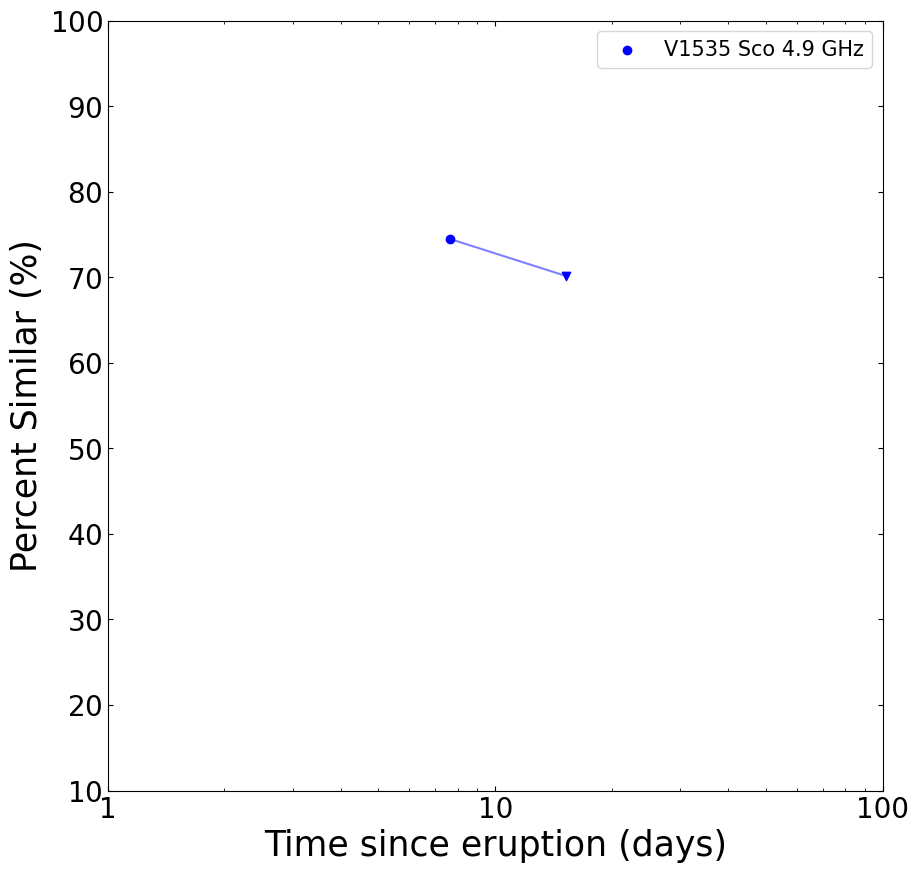

In [169]:
#plotting
fig, ax = plt.subplots()
fig.set_size_inches(10,10)

ax.scatter(day_V1535_5GHz[1], diff_V1535_5GHz[1]*100, color='blue', marker='o', label="V1535 Sco 4.9 GHz")
ax.scatter(day_V1535_5GHz[0], diff_V1535_5GHz[0]*100, color='blue', marker='v')
ax.plot(day_V1535_5GHz, diff_V1535_5GHz*100, color='blue', alpha=0.5)

# Final plot formatting
#x-axis
ax.set_xscale('log')
ax.set_xticks([1, 10,100], labels = ['1','10','100'], fontsize = 20)
ax.set_xlabel("Time since eruption (days)", fontsize = 25)
#y-axis
#ax.set_yscale('log')
ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels = [r'$10$', r'$20$', r'$30$', r'$40$', r'$50$', r'$60$', r'$70$', r'$80$', r'$90$', r'$100$'], fontsize = 20)
ax.set_ylabel("Percent Similar (%)", fontsize = 25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.set_title("")
plt.legend(fontsize = 15)
#plt.savefig("V1535Sco_VLA_vs_VLBA_percent_.png")
plt.show()

# RS Oph (2021 eruption)

## 1.6 GHz and 5 GHz

### 1.6 GHz

In [170]:
#VLBA data
#From Lico et al. 2024

f1_VLBI = (
    [15, 1.6, 79.3, 7.9], #epoch 1
    [25, 1.6, 64.8, 6.5], #epoch 2
    [35, 1.6, 48.3, 4.8], #epoch 3
    #[50, 1.6, ], #epoch 4
    [65, 1.6, 36.7, 3.7], #epoch 5
)

#making the dataframes for the frequency
VLBI_RSOph_1 = pd.DataFrame(f1_VLBI, columns = ["Days","Freq","Flux","Error"])
days1_VLBI = VLBI_RSOph_1['Days']
flux1_VLBI = VLBI_RSOph_1["Flux"]
flux_err1_VLBI = np.sqrt(VLBI_RSOph_1["Error"]**2 + (VLBI_RSOph_1["Flux"]*0.05)**2)

In [171]:
#VLA data
#2.6 GHz is the closest we have in the VLA data

f2_6 = (
    #[59439.04,	2.6,	4.71,	0.14],
    #[59440.08,	2.6,	18.206,	0.11],
    #[59443.99,	2.6,	68.929,	0.37],
    #[59446.01,	2.6,	88.695,	0.21],
    [59446.99,	2.6,	84.443,	0.34], #Day 13 (12.99), 2 days off
    #[59451.01,	2.6,	92.534,	0.24],	
    [59461.01,	2.6,	94.467,	0.22], # Day 27 (27.01), 2 days off
    #[59463.02,	2.6,	88.638,	0.2],		
    #[59466.04,	2.6,	58.862,	0.17],			
    #[59467.99,	2.6,	81.96,	0.23],
    [59470.01,	2.6,	74.216,	0.24], # Day 36 (36.01), 1 day off
    [59487.96,	2.6,	65.358,	0.18], # day 54 (53.96), 11 days off
    #[59510.94,	2.6,	27.414,	0.13], #day 77 (76.94), 12 days off
    #[59511.92,	2.6,	36.139,	0.13],
    #[59523.82,	2.6,	32.964,	0.13],		
    #[59574.76,	2.6,	17.902,	0.2],
    #[59588.66,	2.6,	24.59,	0.16],
    #[59590.61,	2.6,	24.388,	0.21],
    #[59595.61,	2.6,	23.163,	0.16],
    #[60034.47,	2.6,	3.295,	0.17],
    #[60049.34,	2.6,	2.777,	0.17],
    #[60131.12,	2.6,	1.808,	0.017],
)

VLA_RSOph_df2_6 =  pd.DataFrame(f2_6, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])
VLA_RSOph_days2_6 = VLA_RSOph_df2_6['MJD'] - 59434
VLA_RSOph_flux2_6 = VLA_RSOph_df2_6["Flux Density (mJy)"]
VLA_RSOph_flux_err2_6 = np.sqrt(VLA_RSOph_df2_6["Uncertainty (mJy)"]**2 + (VLA_RSOph_df2_6["Flux Density (mJy)"]*0.05)**2)

In [172]:
#finding the difference between the VLBI and VLA data
diff_RSOph_1GHz = flux1_VLBI / VLA_RSOph_flux2_6


#averaging the days
day_RSOph_1GHz = (VLA_RSOph_days2_6 + days1_VLBI)/2

### 5 GHz

In [173]:
#VLBA data
#From Lico et al. 2024

f5_VLBI = (
    [14, 5, 41.5, 4.2], #epoch 1
    [24, 5, 43.8, 4.4], #epoch 2
    [34, 5, 29.5, 3.0], #epcoh 3
    #[49, 5, ], #epoch 4
    [64, 5, 18.0, 1.8] #epoch 5
)

#making the dataframes for the frequency
VLBI_RSOph_5 = pd.DataFrame(f5_VLBI, columns = ["Days","Freq","Flux","Error"])
days5_VLBI = VLBI_RSOph_5['Days']
flux5_VLBI = VLBI_RSOph_5["Flux"]
flux_err5_VLBI = np.sqrt(VLBI_RSOph_5["Error"]**2 + (VLBI_RSOph_5["Flux"]*0.05)**2)

In [174]:
#VLA data
f5_1 = (
    #[59439.04,	5.1,	10.012,	0.058],
    #[59440.08,	5.1,	33.454,	0.059],
    #[59443.99,	5.1,	67.597,	0.087],
    #[59446.01,	5.1,	60.457,	0.065],
    [59446.99,	5.1,	63.977,	0.083], #day 13 (12.99), 1 day off
    #[59451.01,	5.1,	61.832,	0.074],
    [59461.01,	5.1,	65.115,	0.074], #day 27 (27.01), 3 days off
    #[59463.02,	5.1,	60.766,	0.069],
    #[59466.04,	5.1,	54.499,	0.067],
    [59467.99,	5.1,	60.253,	0.061], #day 34 (33.99), 0 days off
    #[59470.01,	5.1,	56.608,	0.058],
    [59487.96,	5.1,	49.879,	0.061], #day 54 (53.96), 10 days off
    #[59510.94,	5.1,	36.454,	0.052],
    #[59511.92,	5.1,	36.228,	0.053],
    #[59523.82,	5.1,	31.849,	0.053],
    #[59574.76,	5.1,	17.481,	0.064],
    #[59588.66,	5.1,	18.554,	0.06],
    #[59590.61,	5.1,	19.794,	0.062],
    #[59595.61,	5.1,	17.488,	0.056],
    #[60034.47,	5.1,	2.765,	0.052],
    #[60049.34,	5.1,	2.684,	0.053],
    #[60131.12,	5.1,	2.163,	0.016],
)


VLA_RSOph_df5_1 =  pd.DataFrame(f5_1, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])
days5_1_VLA_RSOph = VLA_RSOph_df5_1['MJD'] - 59434
flux5_1_VLA_RSOph = VLA_RSOph_df5_1["Flux Density (mJy)"]
flux_err5_1_VLA_RSOph = np.sqrt(VLA_RSOph_df5_1["Uncertainty (mJy)"]**2 + (VLA_RSOph_df5_1["Flux Density (mJy)"]*0.05)**2)

In [175]:
#finding the difference between the VLBI and VLA data
diff_RSOph_5GHz = flux5_VLBI / flux5_1_VLA_RSOph


#averaging the days
day_RSOph_5GHz = (days5_1_VLA_RSOph + days5_VLBI)/2

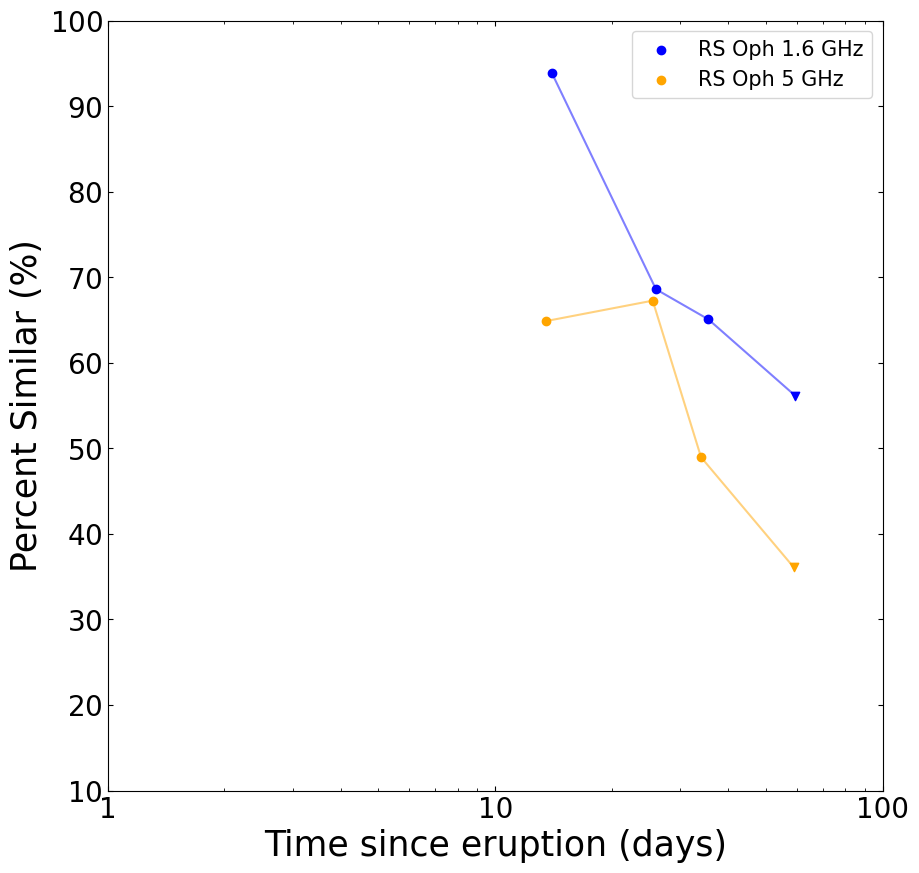

In [176]:
#plotting
fig, ax = plt.subplots()
fig.set_size_inches(10,10)

ax.scatter(day_RSOph_1GHz[0:3], diff_RSOph_1GHz[0:3]*100, color='blue', marker='o', label="RS Oph 1.6 GHz")
ax.scatter(day_RSOph_1GHz[3], diff_RSOph_1GHz[3]*100, color='blue', marker='v')
ax.plot(day_RSOph_1GHz, diff_RSOph_1GHz*100, color='blue', alpha=0.5)

ax.scatter(day_RSOph_5GHz[0:3], diff_RSOph_5GHz[0:3]*100, color='orange', marker='o', label="RS Oph 5 GHz")
ax.scatter(day_RSOph_5GHz[3], diff_RSOph_5GHz[3]*100, color='orange', marker='v')
ax.plot(day_RSOph_5GHz, diff_RSOph_5GHz*100, color='orange', alpha=0.5)

# Final plot formatting
#x-axis
ax.set_xscale('log')
ax.set_xticks([1, 10,100], labels = ['1','10','100'], fontsize = 20)
ax.set_xlabel("Time since eruption (days)", fontsize = 25)
#y-axis
#ax.set_yscale('log')
ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels = [r'$10$', r'$20$', r'$30$', r'$40$', r'$50$', r'$60$', r'$70$', r'$80$', r'$90$', r'$100$'], fontsize = 20)
ax.set_ylabel("Percent Similar (%)", fontsize = 25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.set_title("")
plt.legend(fontsize = 15)
#plt.savefig("RSOph_VLA_vs_VLBA_percent_.png")
plt.show()

# Now all of them on the same plot
## Testing to see if it is too crowded



### Marking meanings
    Stars are 1.6 GHz
    Circles are ~5 GHz
    Squares are 8.6 GHz

    Blue is V407 Cyg
    Gray is V3890 Sgr
    Black is V1535 Sco
    Orange is RS Oph

    Upside down triangles are the day differences to note from the top of the notebook.

    Lines porvided to clearly see the evolution of the percentage frequency relationship


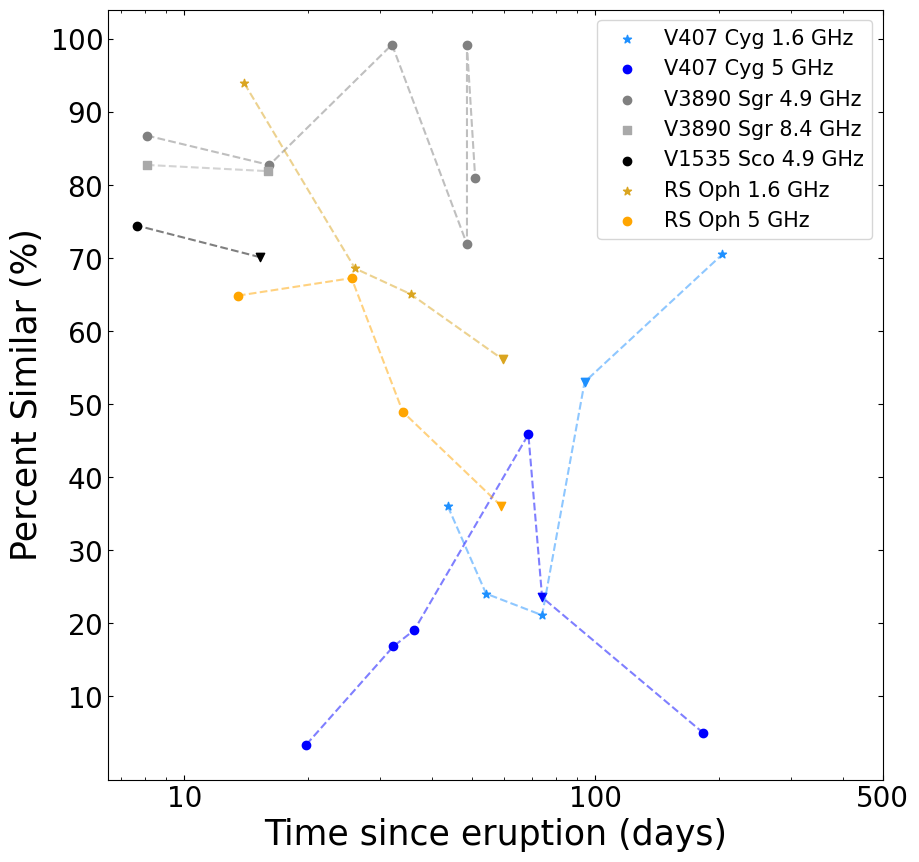

In [185]:
#plotting
fig, ax = plt.subplots()
fig.set_size_inches(10,10)


#V407 Cyg
ax.scatter(day_V407_1GHz, diff_V407_1GHz*100, color='dodgerblue', marker='*', label="V407 Cyg 1.6 GHz")
ax.scatter(day_V407_1GHz_non, diff_V407_1GHz_non*100, color='dodgerblue', marker='v')
ax.plot(day_V407_1GHz_plot, diff_V407_1GHz_plot*100, color='dodgerblue', linestyle='--', alpha=0.5)


ax.scatter(day_V407_5GHz, diff_V407_5GHz*100, color='blue', marker='o', label="V407 Cyg 5 GHz")
ax.scatter(day_V407_5GHz_non, diff_V407_5GHz_non*100, color='blue', marker='v')
ax.plot(day_V407_5GHz_plot, diff_V407_5GHz_plot*100, color='blue', linestyle='--', alpha=0.5)


#V3890 Sgr

ax.scatter(day_V3890_5GHz, diff_V3890_5GHz*100, color='gray', marker='o', label="V3890 Sgr 4.9 GHz")
ax.plot(day_V3890_5GHz, diff_V3890_5GHz*100, color='gray', linestyle='--', alpha=0.5)


ax.scatter(day_V3890_8GHz, diff_V3890_8GHz*100, color='darkgray', marker='s', label="V3890 Sgr 8.4 GHz")
ax.plot(day_V3890_8GHz, diff_V3890_8GHz*100, color='darkgray', linestyle='--', alpha=0.5)

#V1535 Sco

ax.scatter(day_V1535_5GHz[1], diff_V1535_5GHz[1]*100, color='black', marker='o', label="V1535 Sco 4.9 GHz")
ax.scatter(day_V1535_5GHz[0], diff_V1535_5GHz[0]*100, color='black', marker='v')
ax.plot(day_V1535_5GHz, diff_V1535_5GHz*100, color='black', linestyle='--', alpha=0.5)

#RS Oph

ax.scatter(day_RSOph_1GHz[0:3], diff_RSOph_1GHz[0:3]*100, color='goldenrod', marker='*', label="RS Oph 1.6 GHz")
ax.scatter(day_RSOph_1GHz[3], diff_RSOph_1GHz[3]*100, color='goldenrod', marker='v')
ax.plot(day_RSOph_1GHz, diff_RSOph_1GHz*100, color='goldenrod', linestyle='--', alpha=0.5)

ax.scatter(day_RSOph_5GHz[0:3], diff_RSOph_5GHz[0:3]*100, color='orange', marker='o', label="RS Oph 5 GHz")
ax.scatter(day_RSOph_5GHz[3], diff_RSOph_5GHz[3]*100, color='orange', marker='v')
ax.plot(day_RSOph_5GHz, diff_RSOph_5GHz*100, color='orange', linestyle='--', alpha=0.5)


# Final plot formatting
#x-axis
ax.set_xscale('log')
ax.set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 20)
ax.set_xlabel("Time since eruption (days)", fontsize = 25)
#y-axis
#ax.set_yscale('log')
ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], labels = [r'$10$', r'$20$', r'$30$', r'$40$', r'$50$', r'$60$', r'$70$', r'$80$', r'$90$', r'$100$'], fontsize = 20)
ax.set_ylabel("Percent Similar (%)", fontsize = 25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.set_title("")
plt.legend(fontsize = 15)
plt.savefig("VLA_vs_VLBA_percent.png")
plt.show()